# Is the FLT1 module more than the published Ackerman modules, generic co-expression or trophoblast differentiation? (Addendum I)

The original Addendum I was committed before its first run. The corrected I1 baseline and I3 symbol audit were added after external review and are explicitly labelled post-review. Exploratory. Run notebooks 01, 05 and 09 first.

- **I1** Direct comparison with Ackerman et al. 2023 VT Blue and VT Black modules (Table S4).
- **I2** Residual-permutation null that repeats the gene-selection step; donor bootstrap and leave-one-out for V1.
- **I3** Normal CTB → EVT differentiation reference (GSE294617, 3 donors × day 0/3/6, CPM) and a differentiation-score adjustment in both bulk cohorts.

In [1]:
import os, sys, warnings
from pathlib import Path
from urllib.request import urlretrieve
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path(".."); EXT = ROOT / "data_external"
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(EXT / "h.all.v2024.1.Hs.symbols.gmt")}
HYP = set(gmt["HALLMARK_HYPOXIA"])
MODULE = pd.read_csv(RES_DIR / "F1_module_genes.csv").gene.tolist()

def vst_of(counts, groups):
    counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
    md = pd.DataFrame({"g": groups}, index=counts.columns)
    dds = DeseqDataSet(counts=counts.T.astype(int), metadata=md, design="~g", inference=DefaultInference(n_cpus=4), quiet=True)
    dds.fit_size_factors(); dds.vst(use_design=False)
    return pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)
def zs(v): return (v - v.mean()) / v.std()
def hyp_score(vst):
    z = zs(vst); return z[sorted(g for g in HYP if g in z.columns)].mean(axis=1)
def design(covs):
    return np.column_stack([np.ones(len(covs[0]))] + [np.asarray(c, float) for c in covs])
def rank_resid(M, X):
    R = np.apply_along_axis(stats.rankdata, 0, M)
    return R - X @ np.linalg.lstsq(X, R, rcond=None)[0]
def partial_spearman(x, y, covs):
    X = design([stats.rankdata(c) for c in covs])
    e = rank_resid(np.column_stack([x, y]), X); return np.corrcoef(e[:, 0], e[:, 1])[0, 1]

# GSE114691
tx2gene = pd.read_csv(EXT / "grch37_tx2gene.tsv", sep="\t").set_index("Transcript stable ID")["Gene name"]
parts = []
for g, f in {"control": "ControlONLY", "IUGR": "IUGRONLY", "PE": "PEONLY", "PE+IUGR": "PEIUGR"}.items():
    d = pd.read_csv(EXT / f"GSE114691_MasterCount_{f}.txt.gz", sep="\t", index_col=0); d.columns = [f"{g}|{c}" for c in d.columns]; parts.append(d)
tx = pd.concat(parts, axis=1); m = tx.index.isin(tx2gene.index)
gc_r = tx[m].groupby(tx2gene.reindex(tx.index[m]).values).sum().round().astype(int)
grp_r = pd.Series([c.split("|")[0] for c in gc_r.columns], index=gc_r.columns)
vst_r = vst_of(gc_r, grp_r.str.startswith("PE").values); h_r = hyp_score(vst_r)

# GSE203507
counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
vst_d = vst_of(counts, meta.pe_status.values); z_d = zs(vst_d); h_d = hyp_score(vst_d)
pre = meta.index[meta.group != "TB"]

def module_score_d(genes):
    g = [x for x in genes if x in z_d.columns]; return z_d.loc[pre, g].mean(axis=1)
obs_F1 = partial_spearman(module_score_d(MODULE).values, vst_d.loc[pre, "FLT1"].values, [h_d[pre].values])
print(f"F1 module V1 in GSE203507 (recomputed): {obs_F1:.3f}")

F1 module V1 in GSE203507 (recomputed): 0.887


## I1. Published Ackerman et al. 2023 modules (Table S4)

The initial I1 plan used published scores after removing our module genes. After external review, that definition is retained as a sensitivity analysis because it weakens the published baseline. The corrected primary comparison uses the complete published VT Blue and VT Black scores, excluding only FLT1. The correction was documented after the first I1 run and is not presented as pre-specified.

Both definitions test whether the frozen module adds variance in FLT1 after Hallmark hypoxia, published scores and clinical group; a secondary model adds a syncytiotrophoblast marker score. If |Spearman(module, Blue)| > 0.9, the module-versus-Blue distinction is labelled not identifiable regardless of the nested-model p-value.

In [2]:
s4_path = EXT / "NIHMS1883393-supplement-Table_S4.xlsx"
s4 = pd.read_excel(s4_path, sheet_name="TABLE.S4", header=1)
BLUE = set(s4.loc[s4.MODULE.eq("VT Blue"), "SYMBOL"].dropna().astype(str))
BLACK = set(s4.loc[s4.MODULE.eq("VT Black"), "SYMBOL"].dropna().astype(str))
MODULE_SET = set(MODULE)
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
STB = set(markers.loc[markers.cell_class.eq("syncytiotrophoblast"), "gene_symbol"].dropna().astype(str))
print(f"Table S4: {len(BLUE)} VT Blue genes and {len(BLACK)} VT Black genes; disjoint = {BLUE.isdisjoint(BLACK)}")

def mean_z_score(z, genes):
    measured = sorted(set(genes) & set(z.columns))
    return z[measured].mean(axis=1), measured

def nested_module_test(frame, group, include_stb=False):
    columns = ["hyp", "blue", "black"] + (["stb"] if include_stb else [])
    x0 = pd.concat([frame[columns], pd.get_dummies(group, prefix="group", drop_first=True, dtype=float)], axis=1)
    x0 = sm.add_constant(x0, has_constant="add")
    x1 = x0.assign(module=frame.module)
    base = sm.OLS(frame.FLT1, x0).fit(); full = sm.OLS(frame.FLT1, x1).fit()
    f_value, p_value, df_diff = full.compare_f_test(base)
    return {"n": len(frame), "base_r2": base.rsquared, "full_r2": full.rsquared,
            "delta_r2": full.rsquared - base.rsquared, "f_add_module": f_value,
            "df_diff": df_diff, "p_nested_f": p_value,
            "module_beta": full.params["module"], "module_p": full.pvalues["module"]}

z_r = zs(vst_r)
overlap_rows, model_rows = [], []
for cohort, vst, z, idx, groups in [
    ("GSE203507", vst_d, z_d, pre, meta.loc[pre, "group"]),
    ("GSE114691", vst_r, z_r, vst_r.index, grp_r),
]:
    universe = set(z.columns); measured_module = MODULE_SET & universe
    for published_name, published in [("VT Blue", BLUE), ("VT Black", BLACK)]:
        measured_published = published & universe; overlap = measured_module & measured_published
        overlap_rows.append({"cohort": cohort, "published_module": published_name,
            "background_genes": len(universe), "our_module_measured": len(measured_module),
            "published_measured": len(measured_published), "overlap": len(overlap),
            "fraction_of_our_module": len(overlap) / len(measured_module),
            "jaccard": len(overlap) / len(measured_module | measured_published),
            "hypergeom_p": stats.hypergeom.sf(len(overlap) - 1, len(universe), len(measured_published), len(measured_module)) if overlap else 1.0,
            "overlap_genes": ";".join(sorted(overlap))})

    frame_common = pd.DataFrame(index=idx)
    frame_common["FLT1"] = vst.loc[idx, "FLT1"]
    frame_common["module"], module_genes = mean_z_score(z.loc[idx], measured_module)
    frame_common["hyp"], hyp_genes = mean_z_score(z.loc[idx], HYP & universe)
    stb_genes = (STB - MODULE_SET - {"FLT1"}) & universe
    frame_common["stb"], stb_score_genes = mean_z_score(z.loc[idx], stb_genes)

    score_definitions = [
        ("full_published_primary", (BLUE - {"FLT1"}) & universe, (BLACK - {"FLT1"}) & universe),
        ("overlap_free_sensitivity", (BLUE - MODULE_SET - {"FLT1"}) & universe, (BLACK - MODULE_SET - {"FLT1"}) & universe),
    ]
    for score_definition, blue_genes, black_genes in score_definitions:
        frame = frame_common.copy()
        frame["blue"], blue_score_genes = mean_z_score(z.loc[idx], blue_genes)
        frame["black"], black_score_genes = mean_z_score(z.loc[idx], black_genes)
        rho_blue = stats.spearmanr(frame.module, frame.blue).statistic
        rho_black = stats.spearmanr(frame.module, frame.black).statistic
        for include_stb in [False, True]:
            result = nested_module_test(frame, groups.loc[idx], include_stb)
            result.update({"cohort": cohort, "published_score_definition": score_definition,
                "stb_adjustment": include_stb,
                "n_module_genes": len(module_genes), "n_blue_score_genes": len(blue_score_genes),
                "n_black_score_genes": len(black_score_genes), "n_hypoxia_genes": len(hyp_genes),
                "n_stb_marker_genes": len(stb_score_genes) if include_stb else 0,
                "rho_module_blue": rho_blue, "rho_module_black": rho_black,
                "identifiable": abs(rho_blue) <= 0.9})
            model_rows.append(result)

i1_overlap = pd.DataFrame(overlap_rows)
i1_models = pd.DataFrame(model_rows)
i1_overlap.to_csv(RES_DIR / "I1_ackerman_overlap.csv", index=False)
i1_models.to_csv(RES_DIR / "I1_ackerman_models.csv", index=False)
print("\nOverlap with published modules:")
print(i1_overlap.drop(columns="overlap_genes").round(4).to_string(index=False))
print("\nNested FLT1 models (full published scores are primary):")
print(i1_models.round(4).to_string(index=False))
print("\nPre-specified identifiability reading is retained: |rho(module, Blue)| > 0.9 means not identifiable. GSE114691 remains descriptive because it was used to select the FLT1-centred module.")

Table S4: 1001 VT Blue genes and 391 VT Black genes; disjoint = True

Overlap with published modules:
   cohort published_module  background_genes  our_module_measured  published_measured  overlap  fraction_of_our_module  jaccard  hypergeom_p
GSE203507          VT Blue             15835                   44                 965       31                  0.7045   0.0317       0.0000
GSE203507         VT Black             15835                   44                 367        3                  0.0682   0.0074       0.0815
GSE114691          VT Blue             28585                   50                 949       31                  0.6200   0.0320       0.0000
GSE114691         VT Black             28585                   50                 361        3                  0.0600   0.0074       0.0253

Nested FLT1 models (full published scores are primary):
 n  base_r2  full_r2  delta_r2  f_add_module  df_diff  p_nested_f  module_beta  module_p    cohort published_score_definition  stb_adjus

## I2. Residual-permutation null (selection repeated; nuisance = hypoxia + clinical group)

In [3]:
G = pd.get_dummies(grp_r, drop_first=True).astype(float).values
Xn = np.column_stack([np.ones(len(h_r)), stats.rankdata(h_r), G])
RES = pd.DataFrame(rank_resid(vst_r.values, Xn), index=vst_r.index, columns=vst_r.columns)
RC = RES - RES.mean(); norms = np.sqrt((RC ** 2).sum())
cand_genes = np.array([g for g in RC.columns if g not in HYP and g != "FLT1"])
RCc = RC[cand_genes].values; normc = norms[cand_genes].values
def select(target):
    t = target - target.mean(); r = (RCc.T @ t) / (normc * np.sqrt((t ** 2).sum()))
    return list(cand_genes[np.argsort(-np.nan_to_num(r, nan=-9))[:50]])
f_res = RC["FLT1"].values
mod_I2 = select(f_res)
obs_I2 = partial_spearman(module_score_d(mod_I2).values, vst_d.loc[pre, "FLT1"].values, [h_d[pre].values])
print(f"Observed module under I2 spec: overlap with F1 module {len(set(mod_I2) & set(MODULE))}/50, V1 = {obs_I2:.3f}")
rng = np.random.default_rng(42); groups = grp_r.values; null = []
for i in range(500):
    perm = f_res.copy()
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]; perm[idx] = f_res[rng.permutation(idx)]
    null.append(partial_spearman(module_score_d(select(perm)).values, vst_d.loc[pre, "FLT1"].values, [h_d[pre].values]))
null = np.array(null); p_I2 = (1 + (null >= obs_I2).sum()) / 501

# donor bootstrap and LOO for the frozen F1 module
ms = module_score_d(MODULE); fl = vst_d.loc[pre, "FLT1"]; hh = h_d[pre]; boots = []
for _ in range(2000):
    s = rng.choice(len(pre), len(pre), replace=True)
    if len(set(s)) < 8: continue
    boots.append(partial_spearman(ms.values[s], fl.values[s], [hh.values[s]]))
loo = [partial_spearman(ms.drop(index=j).values, fl.drop(index=j).values, [hh.drop(index=j).values]) for j in pre]
i2 = pd.DataFrame([{"observed_I2_spec": obs_I2, "null_median": np.median(null), "null_95th": np.quantile(null, .95),
                    "p_selection_null": p_I2, "F1_V1": obs_F1, "F1_boot_CI_low": np.quantile(boots, .025),
                    "F1_boot_CI_high": np.quantile(boots, .975), "F1_loo_min": min(loo), "F1_loo_max": max(loo)}])
i2.to_csv(RES_DIR / "I2_selection_null.csv", index=False); pd.set_option("display.width", 220); print(i2.round(3).T.to_string())

Observed module under I2 spec: overlap with F1 module 44/50, V1 = 0.841


                      0
observed_I2_spec  0.841
null_median      -0.135
null_95th         0.436
p_selection_null  0.002
F1_V1             0.887
F1_boot_CI_low    0.602
F1_boot_CI_high   0.963
F1_loo_min        0.864
F1_loo_max        0.913


## I3. Normal CTB → EVT differentiation reference (GSE294617)

In [4]:
ref_path = EXT / "GSE294617_CPMs_All_Samples.txt.gz"
if not ref_path.exists():
    urlretrieve("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE294nnn/GSE294617/suppl/GSE294617_CPMs_All_Samples.txt.gz", ref_path)
cpm = pd.read_csv(ref_path, sep=r"\s+", index_col=0)
cpm = cpm.groupby(cpm.index).mean()
lay = pd.DataFrame({"col": [f"s104902.001.00{i}" for i in range(1, 10)],
                    "donor": ["D1"] * 3 + ["D2"] * 3 + ["D3"] * 3, "day": [0, 3, 6] * 3}).set_index("col")
L = np.log2(cpm[lay.index] + 1)
L = L.loc[(cpm[lay.index] >= 1).sum(axis=1) >= 3]
Lc = L.sub(L.mean(axis=1), axis=0)

def match_symbol(symbol, target_symbols):
    target_symbols = set(target_symbols)
    if symbol in target_symbols:
        return symbol, "exact"
    alternatives = ({symbol.replace(".", "-"), symbol.replace("-", ".")} - {symbol}) & target_symbols
    if len(alternatives) == 1:
        return next(iter(alternatives)), "dot_hyphen_normalization"
    return None, "unmatched"

def mapped_list(genes, target_symbols):
    mapped = []
    for gene in genes:
        target, _ = match_symbol(gene, target_symbols)
        if target is not None:
            mapped.append(target)
    return list(dict.fromkeys(mapped))

def ref_score(mapped_genes):
    return Lc.loc[mapped_genes].mean(), len(mapped_genes)

module_ref_genes = mapped_list(MODULE, L.index)
hypoxia_ref_genes = mapped_list(HYP, L.index)
mod_r, nm = ref_score(module_ref_genes); hyp_r, nh = ref_score(hypoxia_ref_genes)
traj = lay.copy(); traj["module"] = mod_r; traj["hypoxia"] = hyp_r; traj["FLT1"] = L.loc["FLT1"] if "FLT1" in L.index else np.nan
print(f"Module genes in reference after documented symbol matching: {nm}/50; hypoxia genes: {nh}")
print(traj.pivot(index="donor", columns="day", values="module").round(2))
delta = lambda s: (s[lay.day == 6].values - s[lay.day == 0].values)
dmod = delta(traj.module); dh = delta(traj.hypoxia); df1 = delta(traj.FLT1)
# context: random 50-gene sets matched by mean log2 CPM decile
bins = pd.qcut(L.mean(axis=1), 10, labels=False); mod_in = module_ref_genes
need = bins.loc[mod_in].value_counts().sort_index()
pool = {b: np.array(sorted(set(bins.index[bins == b]) - set(mod_in) - {"FLT1"})) for b in range(10)}
rand = []
for _ in range(1000):
    pick = np.concatenate([rng.choice(pool[b], n, replace=False) for b, n in need.items()])
    rand.append(delta(Lc.loc[pick].mean()).mean())
rand = np.array(rand)
i3 = pd.DataFrame([{"module_d6_minus_d0_per_donor": np.round(dmod, 2).tolist(), "module_mean_change": dmod.mean(),
                    "frac_random_sets_larger": float((rand >= dmod.mean()).mean()),
                    "hypoxia_d6_minus_d0_per_donor": np.round(dh, 2).tolist(), "FLT1_d6_minus_d0_log2_per_donor": np.round(df1, 2).tolist()}])
i3.to_csv(RES_DIR / "I3_reference_trajectory.csv", index=False); print(i3.T.to_string())

Module genes in reference after documented symbol matching: 34/50; hypoxia genes: 158
day       0     3     6
donor                  
D1    -1.18  0.03  0.73
D2    -0.74 -0.04  1.07
D3    -0.98  0.11  1.02


                                                  0
module_d6_minus_d0_per_donor       [1.91, 1.8, 2.0]
module_mean_change                         1.905529
frac_random_sets_larger                         0.0
hypoxia_d6_minus_d0_per_donor    [0.34, 0.52, 0.16]
FLT1_d6_minus_d0_log2_per_donor  [4.27, 6.94, 3.16]


### Differentiation score and symbol audit

The score excludes FLT1, module genes and hypoxia genes. Exact symbols are preferred; `.` ↔ `-` normalization is accepted only for a unique match. The audit distinguishes genes absent from the raw vocabulary from genes removed by expression filtering.

In [5]:
lfc = pd.DataFrame({dn: L[lay.index[(lay.donor == dn) & (lay.day == 6)]].iloc[:, 0] - L[lay.index[(lay.donor == dn) & (lay.day == 0)]].iloc[:, 0]
                    for dn in ["D1", "D2", "D3"]})
up_all = lfc[(lfc > 0).all(axis=1)].mean(axis=1)
up_all = up_all.drop(index=[g for g in up_all.index if g in set(module_ref_genes) | set(hypoxia_ref_genes) | {"FLT1"}], errors="ignore")
DIFF_SOURCE = list(up_all.sort_values(ascending=False).index[:100])

raw_vocab = {"GSE294617 reference": set(cpm.index), "GSE203507": set(counts.index), "GSE114691": set(gc_r.index)}
filtered_vocab = {"GSE294617 reference": set(L.index), "GSE203507": set(vst_d.columns), "GSE114691": set(vst_r.columns)}
mapping_rows = []
for analysis_set, genes, targets in [
    ("FLT1 module in differentiation reference", MODULE, ["GSE294617 reference"]),
    ("Differentiation score in bulk", DIFF_SOURCE, ["GSE203507", "GSE114691"]),
]:
    for dataset in targets:
        for source_symbol in genes:
            raw_match, raw_method = match_symbol(source_symbol, raw_vocab[dataset])
            filtered_match, filtered_method = match_symbol(source_symbol, filtered_vocab[dataset])
            if filtered_match is not None:
                mapped_symbol = filtered_match; mapping_method = filtered_method; included = True; reason = "included"
            elif raw_match is not None:
                mapped_symbol = raw_match; mapping_method = raw_method; included = False; reason = "present_in_raw_but_removed_by_expression_filter"
            else:
                mapped_symbol = ""; mapping_method = "unmatched"; included = False; reason = "absent_from_dataset_vocabulary"
            mapping_rows.append({"analysis_set": analysis_set, "source_symbol": source_symbol,
                "target_dataset": dataset, "mapped_symbol": mapped_symbol,
                "mapping_method": mapping_method, "present_in_raw": raw_match is not None,
                "present_after_filter": filtered_match is not None, "included_in_score": included,
                "exclusion_reason": reason})

mapping = pd.DataFrame(mapping_rows)
mapping.to_csv(RES_DIR / "I3_gene_symbol_mapping.csv", index=False)

# A canonical display symbol is changed only when both bulk vocabularies give the same unique punctuation-normalized match.
canonical = []
for gene in DIFF_SOURCE:
    matches = [match_symbol(gene, raw_vocab[d])[0] for d in ["GSE203507", "GSE114691"]]
    non_null = {m for m in matches if m is not None}
    canonical.append(next(iter(non_null)) if len(non_null) == 1 else gene)
pd.DataFrame({"gene": DIFF_SOURCE, "canonical_symbol": canonical}).to_csv(RES_DIR / "I3_differentiation_genes.csv", index=False)
print("Top differentiation genes:", ", ".join(DIFF_SOURCE[:15]), "...")
print("Symbol mapping coverage:")
print(mapping.groupby(["analysis_set", "target_dataset", "mapping_method"]).size().rename("n").to_string())

rows = []
z_r = zs(vst_r)
for cohort, z, vst, h, idx in [("GSE203507 (25 preterm)", z_d, vst_d, h_d, pre), ("GSE114691 (79)", z_r, vst_r, h_r, vst_r.index)]:
    dataset = cohort.split(" ")[0]
    diff_genes = mapping.loc[(mapping.analysis_set == "Differentiation score in bulk") &
                             (mapping.target_dataset == dataset) & mapping.included_in_score, "mapped_symbol"].tolist()
    mod = z.loc[idx, [g for g in MODULE if g in z.columns]].mean(axis=1)
    dif = z.loc[idx, diff_genes].mean(axis=1)
    base = partial_spearman(mod.values, vst.loc[idx, "FLT1"].values, [h[idx].values])
    adj = partial_spearman(mod.values, vst.loc[idx, "FLT1"].values, [h[idx].values, dif.values])
    rows.append({"cohort": cohort, "n_diff_genes": len(diff_genes),
                 "rho(module, diff score)": stats.spearmanr(mod, dif)[0], "rho(FLT1, diff score)": stats.spearmanr(vst.loc[idx, "FLT1"], dif)[0],
                 "partial_rho_hypoxia_only": base, "partial_rho_+differentiation": adj, "drop_pct": (base - adj) / base * 100})
i3b = pd.DataFrame(rows); i3b.to_csv(RES_DIR / "I3_differentiation_adjustment.csv", index=False); print(i3b.round(3).to_string(index=False))
print("Pre-specified reading: differentiation is the leading explanation if the module rises d0->d6 in all donors AND the partial rho drops > 50%.")

Top differentiation genes: CSH1, NOTUM, LAMA4, CSH2, PSG3, DIO2, ACAN, ISM2, CSF2RB, SLCO4A1, LRRC32, MMP2, MYCNUT, CGB5, CGB8 ...
Symbol mapping coverage:
analysis_set                              target_dataset       mapping_method          
Differentiation score in bulk             GSE114691            dot_hyphen_normalization     1
                                                               exact                       90
                                                               unmatched                    9
                                          GSE203507            dot_hyphen_normalization     1
                                                               exact                       92
                                                               unmatched                    7
FLT1 module in differentiation reference  GSE294617 reference  exact                       34
                                                               unmatched                   16
    

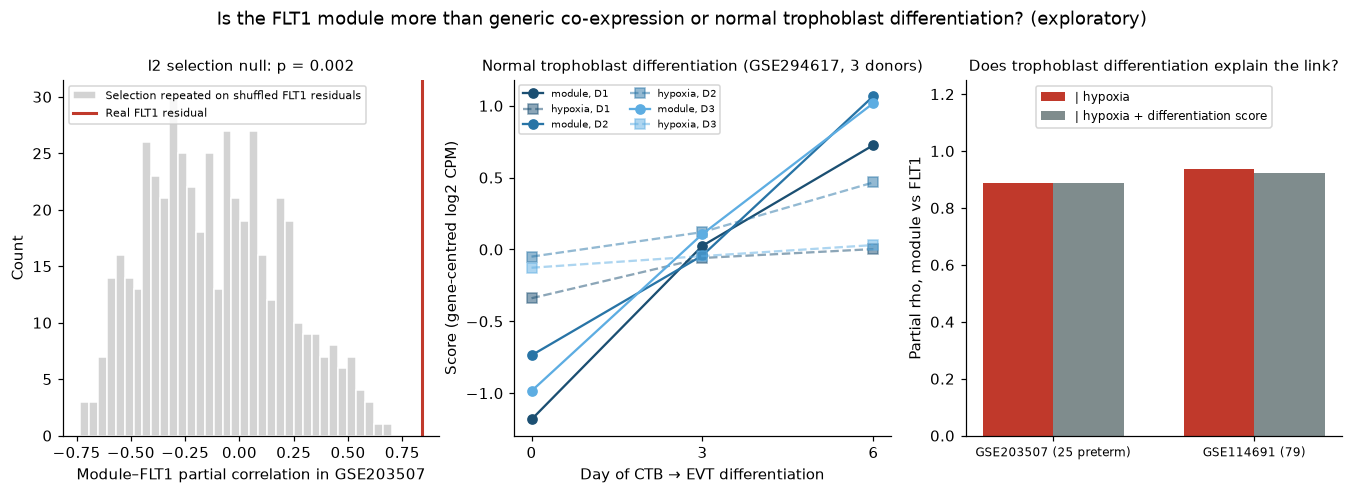

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ax.hist(null, bins=35, color="lightgrey", edgecolor="white", label="Selection repeated on shuffled FLT1 residuals")
ax.axvline(obs_I2, c="#c0392b", lw=2, label="Real FLT1 residual")
ax.set_xlabel("Module–FLT1 partial correlation in GSE203507"); ax.set_ylabel("Count"); ax.legend(fontsize=7.5)
ax.set_title(f"I2 selection null: p = {p_I2:.3f}", fontsize=10)
ax = axes[1]
for dn, cc in zip(["D1", "D2", "D3"], ["#1b4f72", "#2874a6", "#5dade2"]):
    t = traj[traj.donor == dn]; ax.plot(t.day, t.module, "-o", c=cc, label=f"module, {dn}")
    ax.plot(t.day, t.hypoxia, "--s", c=cc, alpha=0.5, label=f"hypoxia, {dn}")
ax.set_xticks([0, 3, 6]); ax.set_xlabel("Day of CTB → EVT differentiation"); ax.set_ylabel("Score (gene-centred log2 CPM)")
ax.set_title("Normal trophoblast differentiation (GSE294617, 3 donors)", fontsize=10); ax.legend(fontsize=6.5, ncol=2)
ax = axes[2]
x = np.arange(len(i3b)); w = 0.35
ax.bar(x - w / 2, i3b["partial_rho_hypoxia_only"], w, label="| hypoxia", color="#c0392b")
ax.bar(x + w / 2, i3b["partial_rho_+differentiation"], w, label="| hypoxia + differentiation score", color="#7f8c8d")
ax.set_xticks(x); ax.set_xticklabels(i3b.cohort, fontsize=8); ax.set_ylabel("Partial rho, module vs FLT1"); ax.set_ylim(0, 1.25); ax.legend(fontsize=8, loc="upper center")
ax.set_title("Does trophoblast differentiation explain the link?", fontsize=10)
fig.suptitle("Is the FLT1 module more than generic co-expression or normal trophoblast differentiation? (exploratory)", y=1.03)
plt.savefig(FIG_DIR / "fig15_selection_null_and_differentiation.png", dpi=300, bbox_inches="tight"); plt.show()